<a href="https://colab.research.google.com/github/vichareal/SLP_IRIS_Manda/blob/main/SLP_Iris_Replikasi_Excel_5_Epoch_Manda_593286.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Single Layer Perceptron (SLP) — Iris
### Replikasi langkah demi langkah dari `PMM-SLP_MANDA.xlsx`

**Tujuan:** memperoleh nilai *training loss*, *validation loss*, *training accuracy*, dan *validation accuracy* yang sama dengan sheet **Hasil** di Excel, selama **5 epoch**.


## 1. Import pustaka
`numpy` untuk perhitungan, `pandas` untuk tabel, dan `matplotlib` untuk grafik.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.precision", 10)

## 2. Dataset asli dari Excel
Kolom `X1–X4` = sepal length, sepal width, petal length, petal width; `TARGET`: Setosa = 0, Versicolor = 1.

**Penting:** Excel menggunakan 80 baris training dan 20 baris validation **dengan urutan tetap**, tanpa pengacakan atau normalisasi. Dataset ditanam langsung agar hasil dapat direproduksi.

In [ ]:
training_data = np.array([[5.1, 3.5, 1.4, 0.2, 0.0], [4.9, 3.0, 1.4, 0.2, 0.0], [4.7, 3.2, 1.3, 0.2, 0.0], [4.6, 3.1, 1.5, 0.2, 0.0], [5.0, 3.6, 1.4, 0.2, 0.0], [5.4, 3.9, 1.7, 0.4, 0.0], [4.6, 3.4, 1.4, 0.3, 0.0], [5.0, 3.4, 1.5, 0.2, 0.0], [4.4, 2.9, 1.4, 0.2, 0.0], [4.9, 3.1, 1.5, 0.1, 0.0], [5.4, 3.7, 1.5, 0.2, 0.0], [4.8, 3.4, 1.6, 0.2, 0.0], [4.8, 3.0, 1.4, 0.1, 0.0], [4.3, 3.0, 1.1, 0.1, 0.0], [5.8, 4.0, 1.2, 0.2, 0.0], [5.7, 4.4, 1.5, 0.4, 0.0], [5.4, 3.9, 1.3, 0.4, 0.0], [5.1, 3.5, 1.4, 0.3, 0.0], [5.7, 3.8, 1.7, 0.3, 0.0], [5.1, 3.8, 1.5, 0.3, 0.0], [5.4, 3.4, 1.7, 0.2, 0.0], [5.1, 3.7, 1.5, 0.4, 0.0], [4.6, 3.6, 1.0, 0.2, 0.0], [5.1, 3.3, 1.7, 0.5, 0.0], [4.8, 3.4, 1.9, 0.2, 0.0], [5.0, 3.0, 1.6, 0.2, 0.0], [5.0, 3.4, 1.6, 0.4, 0.0], [5.2, 3.5, 1.5, 0.2, 0.0], [5.2, 3.4, 1.4, 0.2, 0.0], [4.7, 3.2, 1.6, 0.2, 0.0], [4.8, 3.1, 1.6, 0.2, 0.0], [5.4, 3.4, 1.5, 0.4, 0.0], [5.2, 4.1, 1.5, 0.1, 0.0], [5.5, 4.2, 1.4, 0.2, 0.0], [4.9, 3.1, 1.5, 0.1, 0.0], [5.0, 3.2, 1.2, 0.2, 0.0], [5.5, 3.5, 1.3, 0.2, 0.0], [4.9, 3.1, 1.5, 0.1, 0.0], [4.4, 3.0, 1.3, 0.2, 0.0], [5.1, 3.4, 1.5, 0.2, 0.0], [7.0, 3.2, 4.7, 1.4, 1.0], [6.4, 3.2, 4.5, 1.5, 1.0], [6.9, 3.1, 4.9, 1.5, 1.0], [5.5, 2.3, 4.0, 1.3, 1.0], [6.5, 2.8, 4.6, 1.5, 1.0], [5.7, 2.8, 4.5, 1.3, 1.0], [6.3, 3.3, 4.7, 1.6, 1.0], [4.9, 2.4, 3.3, 1.0, 1.0], [6.6, 2.9, 4.6, 1.3, 1.0], [5.2, 2.7, 3.9, 1.4, 1.0], [5.0, 2.0, 3.5, 1.0, 1.0], [5.9, 3.0, 4.2, 1.5, 1.0], [6.0, 2.2, 4.0, 1.0, 1.0], [6.1, 2.9, 4.7, 1.4, 1.0], [5.6, 2.9, 3.6, 1.3, 1.0], [6.7, 3.1, 4.4, 1.4, 1.0], [5.6, 3.0, 4.5, 1.5, 1.0], [5.8, 2.7, 4.1, 1.0, 1.0], [6.2, 2.2, 4.5, 1.5, 1.0], [5.6, 2.5, 3.9, 1.1, 1.0], [5.9, 3.2, 4.8, 1.8, 1.0], [6.1, 2.8, 4.0, 1.3, 1.0], [6.3, 2.5, 4.9, 1.5, 1.0], [6.1, 2.8, 4.7, 1.2, 1.0], [6.4, 2.9, 4.3, 1.3, 1.0], [6.6, 3.0, 4.4, 1.4, 1.0], [6.8, 2.8, 4.8, 1.4, 1.0], [6.7, 3.0, 5.0, 1.7, 1.0], [6.0, 2.9, 4.5, 1.5, 1.0], [5.7, 2.6, 3.5, 1.0, 1.0], [5.5, 2.4, 3.8, 1.1, 1.0], [5.5, 2.4, 3.7, 1.0, 1.0], [5.8, 2.7, 3.9, 1.2, 1.0], [6.0, 2.7, 5.1, 1.6, 1.0], [5.4, 3.0, 4.5, 1.5, 1.0], [6.0, 3.4, 4.5, 1.6, 1.0], [6.7, 3.1, 4.7, 1.5, 1.0], [6.3, 2.3, 4.4, 1.3, 1.0], [5.6, 3.0, 4.1, 1.3, 1.0], [5.5, 2.5, 4.0, 1.3, 1.0]], dtype=float)
validation_data = np.array([[5.0, 3.5, 1.3, 0.3, 0.0], [4.5, 2.3, 1.3, 0.3, 0.0], [4.4, 3.2, 1.3, 0.2, 0.0], [5.0, 3.5, 1.6, 0.6, 0.0], [5.1, 3.8, 1.9, 0.4, 0.0], [4.8, 3.0, 1.4, 0.3, 0.0], [5.1, 3.8, 1.6, 0.2, 0.0], [4.6, 3.2, 1.4, 0.2, 0.0], [5.3, 3.7, 1.5, 0.2, 0.0], [5.0, 3.3, 1.4, 0.2, 0.0], [5.5, 2.6, 4.4, 1.2, 1.0], [6.1, 3.0, 4.6, 1.4, 1.0], [5.8, 2.6, 4.0, 1.2, 1.0], [5.0, 2.3, 3.3, 1.0, 1.0], [5.6, 2.7, 4.2, 1.3, 1.0], [5.7, 3.0, 4.2, 1.2, 1.0], [5.7, 2.9, 4.2, 1.3, 1.0], [6.2, 2.9, 4.3, 1.3, 1.0], [5.1, 2.5, 3.0, 1.1, 1.0], [5.7, 2.8, 4.1, 1.3, 1.0]], dtype=float)
kolom = ["X1", "X2", "X3", "X4", "TARGET"]
df_train = pd.DataFrame(training_data, columns=kolom)
df_val = pd.DataFrame(validation_data, columns=kolom)
print("Training:", df_train.shape, "| Validation:", df_val.shape)
print("Distribusi training:", df_train.TARGET.value_counts().sort_index().to_dict())
print("Distribusi validation:", df_val.TARGET.value_counts().sort_index().to_dict())
display(df_train.head(), df_val.head())

Training: (80, 5) | Validation: (20, 5)
Distribusi training: {0.0: 40, 1.0: 40}
Distribusi validation: {0.0: 10, 1.0: 10}


,X1,X2,X3,X4,TARGET
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0


,X1,X2,X3,X4,TARGET
0,5.0,3.5,1.3,0.3,0.0
1,4.5,2.3,1.3,0.3,0.0
2,4.4,3.2,1.3,0.2,0.0
3,5.0,3.5,1.6,0.6,0.0
4,5.1,3.8,1.9,0.4,0.0


## 3. Rumus Excel dan parameter
- Bias awal `b = 0.5`; bobot awal `w1=w2=w3=w4=0.5`
- Learning rate `η = 0.1`; epoch = 5
- **Dot product:** `z = b + w1×X1 + w2×X2 + w3×X3 + w4×X4` (Excel kolom N)
- **Sigmoid:** `o = 1/(1+exp(-z))` (kolom O)
- **Prediksi:** `1 jika o > 0.5`, selain itu `0` (kolom P; nilai tepat 0.5 diprediksi 0)
- **Error:** `o − target` (kolom Q)
- **Squared error:** `(o − target)²` (kolom R)
- **Akurasi tiap baris:** `1 jika prediksi == target`, selain itu `0` (kolom S)
- **Gradien bias:** `2(o−target)o(1−o)` (kolom V)
- **Gradien bobot i:** `gradien_bias × Xi` (kolom W–Z)
- **Update:** `b_baru = b_lama − η×gradien_bias`; `wi_baru = wi_lama − η×gradien_wi`

**Sangat penting:** pada sheet Training, bobot di baris berikutnya adalah hasil update dari baris sebelumnya, **termasuk ketika berpindah epoch**. Kolom I–M menampilkan bobot **sebelum** update baris tersebut.

In [ ]:
LEARNING_RATE = 0.1
EPOCHS = 5
bias = 0.5
weights = np.full(4, 0.5, dtype=float)
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))
print("Learning rate:", LEARNING_RATE, "| Bobot:", weights, "| Bias:", bias)

Learning rate: 0.1 | Bobot: [0.5 0.5 0.5 0.5] | Bias: 0.5


## 4. Demonstrasi satu baris perhitungan
Meniru **baris 5 Excel** (data training pertama). Nilai awal: `z=5.6`, sigmoid ≈ `0.9963157601`.

In [ ]:
x = training_data[0,:4]
y = training_data[0,4]
z = bias + np.dot(weights,x)
o = sigmoid(z)
pred = int(o > 0.5)
error = o-y
loss = error**2
grad_b = 2*error*o*(1-o)
grad_w = grad_b*x
print(f"x={x}, target={y:.0f}")
print(f"z={z:.12f}; sigmoid={o:.12f}; prediksi={pred}; error={error:.12f}; SSE={loss:.12f}")
print(f"gradien bias={grad_b:.12f}; gradien bobot={grad_w}")
print("Bias setelah update:",bias-LEARNING_RATE*grad_b)
print("Bobot setelah update:",weights-LEARNING_RATE*grad_w)
assert np.isclose(z,5.6)
assert np.isclose(o,0.9963157601005641)

x=[5.1 3.5 1.4 0.2], target=0
z=5.600000000000; sigmoid=0.996315760101; prediksi=1; error=0.996315760101; SSE=0.992645093825
gradien bias=0.007314285321; gradien bobot=[0.03730286 0.0256     0.01024    0.00146286]
Bias setelah update: 0.4992685714678703
Bobot setelah update: [0.49626971 0.49744    0.498976   0.49985371]


## 5. Training dan validasi mengikuti Excel secara tepat
**Training:** proses 80 sampel secara berurutan, update bobot **setelah setiap sampel** (online / stochastic gradient descent, tanpa shuffle). Rata-rata loss dan accuracy dihitung dari hasil **sebelum update tiap sampel**, bukan mengevaluasi ulang dengan bobot akhir epoch.

**Validation:** setelah semua 80 sampel selesai, gunakan bobot yang sudah diperbarui dari sampel ke-80. Ini sama dengan mengambil bobot di **baris pertama epoch berikutnya**: misalnya validasi epoch 1 mengacu pada bobot Excel `SLP-Training!I85:M85`, bukan `I84:M84`. **Tidak ada update bobot saat validasi.**

In [ ]:
catatan_train = []
catatan_val = []
ringkasan = []
b = 0.5
w = np.full(4, 0.5, dtype=float)

for epoch in range(1,EPOCHS+1):
    hasil_train = []
    for nomor, data in enumerate(training_data, start=1):
        x, target = data[:4], int(data[4])
        b_sebelum, w_sebelum = b, w.copy()
        z = b + float(np.dot(w,x))
        output = float(sigmoid(z))
        prediksi = int(output > 0.5)
        error = output-target
        squared_error = error**2
        benar = int(prediksi==target)
        grad_bias = 2*error*(1-output)*output
        grad_bobot = grad_bias*x
        hasil_train.append((squared_error,benar))
        catatan_train.append(dict(Epoch=epoch,No=nomor,X1=x[0],X2=x[1],X3=x[2],X4=x[3],TARGET=target,
             bias=b_sebelum,teta1=w_sebelum[0],teta2=w_sebelum[1],teta3=w_sebelum[2],teta4=w_sebelum[3],
             z=z,Sigmoid=output,Prediksi=prediksi,error=error,Sum_Square_Error=squared_error,Akurasi=benar,
             dbias=grad_bias,dteta1=grad_bobot[0],dteta2=grad_bobot[1],dteta3=grad_bobot[2],dteta4=grad_bobot[3]))
        b -= LEARNING_RATE*grad_bias
        w -= LEARNING_RATE*grad_bobot

    hasil_val = []
    for nomor, data in enumerate(validation_data,start=1):
        x, target = data[:4], int(data[4])
        z = b + float(np.dot(w,x))
        output = float(sigmoid(z))
        prediksi = int(output>0.5)
        error = output-target
        squared_error = error**2
        benar = int(prediksi==target)
        hasil_val.append((squared_error,benar))
        catatan_val.append(dict(Epoch=epoch,No=nomor,X1=x[0],X2=x[1],X3=x[2],X4=x[3],TARGET=target,
            bias=b,teta1=w[0],teta2=w[1],teta3=w[2],teta4=w[3],z=z,Sigmoid=output,Prediksi=prediksi,
            error=error,Sum_Square_Error=squared_error,Akurasi=benar))

    ringkasan.append(dict(Epoch=epoch,Training_Loss=np.mean([r[0] for r in hasil_train]),
         Validation_Loss=np.mean([r[0] for r in hasil_val]),
         Training_Accuracy=np.mean([r[1] for r in hasil_train]),
         Validation_Accuracy=np.mean([r[1] for r in hasil_val])))

detail_train = pd.DataFrame(catatan_train)
detail_val = pd.DataFrame(catatan_val)
hasil = pd.DataFrame(ringkasan)
print("HASIL 5 EPOCH (replikasi Excel)")
display(hasil)
print("\nContoh 5 baris training pertama:")
display(detail_train.head())
print("\nContoh 5 baris validasi pertama:")
display(detail_val.head())

HASIL 5 EPOCH (replikasi Excel)


,Epoch,Training_Loss,Validation_Loss,Training_Accuracy,Validation_Accuracy
0,1,0.4498886551,0.3289511566,0.5250,0.50
1,2,0.0374519142,0.2472893233,0.9500,0.50
2,3,0.0243721950,0.1758916407,0.9750,0.50
3,4,0.0173572017,0.1193813733,0.9750,0.85
4,5,0.0127401582,0.0815813694,0.9875,1.00



Contoh 5 baris training pertama:


,Epoch,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,...,Sigmoid,Prediksi,error,Sum_Square_Error,Akurasi,dbias,dteta1,dteta2,dteta3,dteta4
0,1,1,5.1,3.5,1.4,0.2,0,0.5000000000,0.5000000000,0.5000000000,...,0.9963157601,1,0.9963157601,0.9926450938,0,0.0073142853,0.0373028551,0.0255999986,0.0102399994,0.0014628571
1,1,2,4.9,3.0,1.4,0.2,0,0.4992685715,0.4962697145,0.4974400001,...,0.9946316257,1,0.9946316257,0.9892920708,0,0.0106217803,0.0520467234,0.0318653408,0.0148704924,0.0021243561
2,1,3,4.7,3.2,1.3,0.2,0,0.4982063934,0.4910650421,0.4942534661,...,0.9941444179,1,0.9941444179,0.9883231236,0,0.0115744144,0.0543997476,0.0370381260,0.0150467387,0.0023148829
3,1,4,4.6,3.1,1.5,0.2,0,0.4970489520,0.4856250674,0.4905496535,...,0.9939129530,1,0.9939129530,0.9878629582,0,0.0120263365,0.0553211479,0.0372816431,0.0180395047,0.0024052673
4,1,5,5.0,3.6,1.4,0.2,0,0.4958463184,0.4800929526,0.4868214891,...,0.9956816524,1,0.9956816524,0.9913819529,0,0.0085622637,0.0428113187,0.0308241495,0.0119871692,0.0017124527



Contoh 5 baris validasi pertama:


,Epoch,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta3,teta4,z,Sigmoid,Prediksi,error,Sum_Square_Error,Akurasi
0,1,1,5.0,3.5,1.3,0.3,0,0.3803361212,-0.0191331249,0.0714465582,0.5244493292,0.5511401686,1.3818596289,0.7992894987,1,0.7992894987,0.6388637028,0
1,1,2,4.5,2.3,1.3,0.3,0,0.3803361212,-0.0191331249,0.0714465582,0.5244493292,0.5511401686,1.3056903215,0.7867910971,1,0.7867910971,0.6190402305,0
2,1,3,4.4,3.2,1.3,0.2,0,0.3803361212,-0.0191331249,0.0714465582,0.5244493292,0.5511401686,1.3167915195,0.7886474037,1,0.7886474037,0.6219647273,0
3,1,4,5.0,3.5,1.6,0.6,0,0.3803361212,-0.0191331249,0.0714465582,0.5244493292,0.5511401686,1.7045364782,0.8461262967,1,0.8461262967,0.7159297100,0
4,1,5,5.1,3.8,1.9,0.4,0,0.3803361212,-0.0191331249,0.0714465582,0.5244493292,0.5511401686,1.7711638982,0.8546023535,1,0.8546023535,0.7303451825,0


## 6. Verifikasi angka dengan sheet `Hasil` di Excel
Nilai referensi berikut berasal dari **cached values** pada file Excel yang diunggah. `np.allclose` memeriksa apakah nilai Python cocok hingga toleransi numerik yang sangat kecil.

In [ ]:
referensi_excel = pd.DataFrame([[1, 0.4498886551395292, 0.3289511565546991, 0.525, 0.5], [2, 0.0374519142280995, 0.24728932330356232, 0.95, 0.5], [3, 0.024372194996393773, 0.1758916406671348, 0.975, 0.5], [4, 0.017357201678426602, 0.1193813732929733, 0.975, 0.85], [5, 0.012740158208926558, 0.08158136941106597, 0.9875, 1]],columns=["Epoch","Training_Loss","Validation_Loss","Training_Accuracy","Validation_Accuracy"])
kolom_hasil = ["Training_Loss","Validation_Loss","Training_Accuracy","Validation_Accuracy"]
perbandingan = hasil[["Epoch"]].copy()
for nama in kolom_hasil:
    perbandingan[nama+" (Python)"] = hasil[nama]
    perbandingan[nama+" (Excel)"] = referensi_excel[nama]
    perbandingan["Selisih "+nama] = hasil[nama]-referensi_excel[nama]
display(perbandingan)
assert np.allclose(hasil[kolom_hasil].to_numpy(),referensi_excel[kolom_hasil].to_numpy(),rtol=1e-10,atol=1e-12), "Hasil berbeda dari Excel: periksa data/rumus!"
print("✅ BERHASIL: seluruh loss dan accuracy dari 5 epoch sesuai Excel (dalam toleransi floating point).")

,Epoch,Training_Loss (Python),Training_Loss (Excel),Selisih Training_Loss,Validation_Loss (Python),Validation_Loss (Excel),Selisih Validation_Loss,Training_Accuracy (Python),Training_Accuracy (Excel),Selisih Training_Accuracy,Validation_Accuracy (Python),Validation_Accuracy (Excel),Selisih Validation_Accuracy
0,1,0.4498886551,0.4498886551,0.0000000000e+00,0.3289511566,0.3289511566,0.0000000000e+00,0.5250,0.5250,0.0,0.50,0.50,0.0
1,2,0.0374519142,0.0374519142,0.0000000000e+00,0.2472893233,0.2472893233,-2.7755575616e-17,0.9500,0.9500,0.0,0.50,0.50,0.0
2,3,0.0243721950,0.0243721950,-6.9388939039e-18,0.1758916407,0.1758916407,-5.5511151231e-17,0.9750,0.9750,0.0,0.50,0.50,0.0
3,4,0.0173572017,0.0173572017,-1.3877787808e-17,0.1193813733,0.1193813733,-5.5511151231e-17,0.9750,0.9750,0.0,0.85,0.85,0.0
4,5,0.0127401582,0.0127401582,8.6736173799e-18,0.0815813694,0.0815813694,-1.3877787808e-17,0.9875,0.9875,0.0,1.00,1.00,0.0


✅ BERHASIL: seluruh loss dan accuracy dari 5 epoch sesuai Excel (dalam toleransi floating point).


## 7. Grafik loss dan accuracy
Loss adalah **mean squared error (MSE)**, yaitu rata-rata kolom squared error di Excel. Grafik accuracy menggunakan nilai 0–100%.

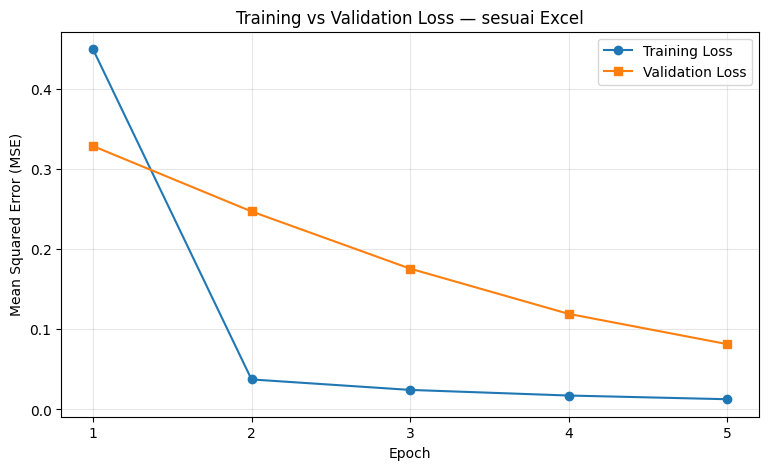

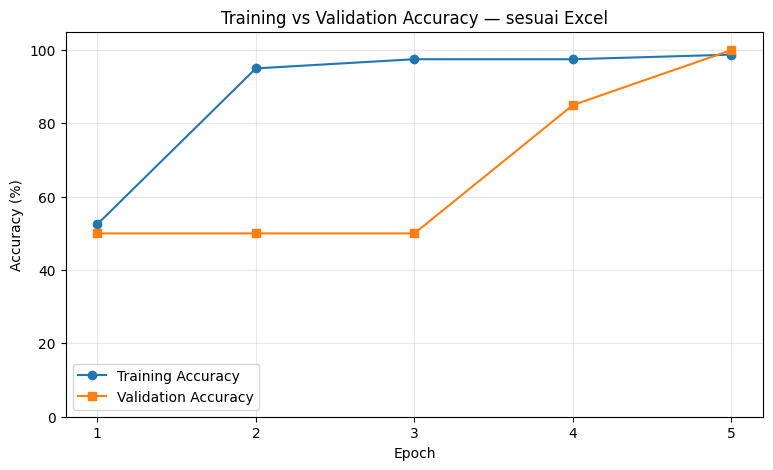

In [ ]:
plt.figure(figsize=(9,5))
plt.plot(hasil.Epoch,hasil.Training_Loss,marker="o",label="Training Loss")
plt.plot(hasil.Epoch,hasil.Validation_Loss,marker="s",label="Validation Loss")
plt.xticks(range(1,6));plt.xlabel("Epoch");plt.ylabel("Mean Squared Error (MSE)")
plt.title("Training vs Validation Loss — sesuai Excel");plt.grid(alpha=.3);plt.legend();plt.show()
plt.figure(figsize=(9,5))
plt.plot(hasil.Epoch,hasil.Training_Accuracy*100,marker="o",label="Training Accuracy")
plt.plot(hasil.Epoch,hasil.Validation_Accuracy*100,marker="s",label="Validation Accuracy")
plt.xticks(range(1,6));plt.ylim(0,105);plt.xlabel("Epoch");plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy — sesuai Excel");plt.grid(alpha=.3);plt.legend();plt.show()

## 8. Interpretasi hasil
- **Epoch 1:** bobot awal masih belum sesuai sehingga training loss besar dan akurasi training rendah.
- **Epoch 2–5:** training loss menurun dan akurasi training meningkat.
- **Validation:** pada epoch awal akurasi tertahan di 50%, kemudian membaik menjadi 85% (epoch 4) dan 100% (epoch 5).
- **Kesimpulan terbatas:** dalam lima epoch ini tidak terlihat pola overfitting dari metrik validasi; kedua loss menurun. Tetapi hanya ada 20 sampel validasi dan belum ada test set independen, jadi belum cukup untuk mengklaim generalisasi sempurna.

**Catatan penting untuk laporan:** training accuracy di sini dihitung secara *online* sepanjang proses perubahan bobot. Jadi tidak sama dengan akurasi training yang dihitung ulang menggunakan bobot akhir epoch. Ini disengaja agar identik dengan Excel.